<a href="https://colab.research.google.com/github/edgmattounhv-boop/Laboratorio-2A-Calidad-Datos/blob/master/S3S4_parte2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ciencia de Datos e IA Aplicada · Sesiones 3 y 4
## Parte 2 · Laboratorio B · Modelos de ensamble (Python)

**Docente:** Doris Elena Campo Duarte · Escuela de Posgrado, Universidad Peruana Unión

---

## Para qué es este laboratorio

Con las mismas 569 biopsias de la parte 1, construyes modelos que predicen si un tumor es maligno. Partes de **un solo árbol de decisión**, lo comparas con **Random Forest** (bagging), **XGBoost** y **LightGBM** (boosting) y con una línea base lineal (**Elastic Net**); ajustas XGBoost con **Optuna**, combinas modelos con **stacking**, estimas el desempeño sin optimismo, revisas **qué errores comete el modelo** y automatizas la comparación para aplicarla a tu dataset.

**Dónde trabajas:** en **Google Colab**, un cuaderno Jupyter en la nube que ejecuta **Python** sin instalar nada. Usamos Python en esta parte porque las librerías de referencia para ensambles y ajuste de hiperparámetros (scikit-learn, XGBoost, LightGBM, Optuna) se usan principalmente desde Python.

**Antes de empezar:** **Archivo → Guardar una copia en Drive** y verifica en **Entorno de ejecución → Cambiar tipo de entorno de ejecución** que esté seleccionado **Python 3**.

> **Por qué partimos de las variables originales:** los árboles (y por tanto Random Forest, XGBoost y LightGBM) no necesitan escalar ni transformar las variables, porque solo comparan valores con umbrales. La receta de la parte 1 es la que aplicarás cuando uses modelos lineales o de distancias. Elastic Net, que sí la necesita, lleva su escalado dentro de un *pipeline*.

> **Métrica principal: AUC** (área bajo la curva ROC). Vale 0,5 si el modelo acierta como el azar y 1 si separa perfectamente. No depende de un umbral y tolera el desbalance moderado de clases.

## Ruta


| Paso | Qué haces | Para qué

|---|---|---|---|
| B0 | Entorno, datos y partición | Preparar Python y entender exactamente cómo se reparten los datos.
| B1 | Del árbol a los ensambles | Ver por qué combinar árboles mejora a un solo árbol y comparar bagging con boosting.
| B2 | Ajuste bayesiano con Optuna | Encontrar buenos hiperparámetros de XGBoost con pocas pruebas.
| B3 | Stacking y blending | Combinar modelos heterogéneos con un meta-modelo, de dos maneras.
| B4 | Evaluación honesta e IA responsable | Estimar sin optimismo, evaluar una sola vez y revisar el costo de los errores.
| B5 | Automatizar la comparación | Repetir todo el proceso con una sola línea, para aplicarlo a tu dataset.

Ejecuta las celdas **en orden** con `Ctrl + Enter` o el botón ▶. Cada celda tiene el mismo número que su diapositiva.

Debajo de cada celda hay una sección **«Prompts listos para copiar»**: ya incluye el código de esa celda, así que solo copias el recuadro completo y lo pegas en el chat de IA que uses (Gemini, ChatGPT, Copilot u otro).

## IA responsable en este laboratorio

La IA responsable no se limita a usar bien un asistente: abarca los datos, el modelo, la interpretación y las herramientas.

| Dimensión | Qué hacemos en este laboratorio |
|---|---|
| **Datos** | Usamos un dataset público y anonimizado (el `id` no identifica a ninguna persona). Con tu dataset: trabaja con la versión anonimizada y no subas datos personales a la nube ni a repositorios públicos. |
| **Proceso** | Separamos entrenamiento y prueba antes de transformar, documentamos cada decisión y dejamos todo reproducible en GitHub. |
| **Modelo e interpretación** | Reportamos la variabilidad, no solo el mejor número; revisamos qué errores comete el modelo y no sobreinterpretamos gráficos exploratorios. |
| **Asistentes de IA** | La IA sugiere; tú ejecutas, verificas y declaras. Pega código y salidas, nunca datos personales. |

| Para qué | Prompt |
|---|---|
| Entender el código | «Explícame línea por línea qué hace este código y por qué se usa aquí: [pega el código]» |
| Resolver un error | «Al ejecutar este código obtengo este error: [pega el error]. Explícame la causa y cómo corregirlo sin cambiar el propósito.» |
| Interpretar un resultado | «Obtuve esta salida: [pega la salida]. ¿Cómo la interpreto respecto de mi hipótesis? No uses datos que no estén en la salida.» |
| Adaptarlo a tu dataset | «Mi dataset tiene estas variables: [pega la estructura]. Adapta este código a mis variables y justifica cada paso.» |

# Paso B0 · Entorno, datos y partición

| | |
|---|---|
| **Para qué** | Preparar Python y entender exactamente cómo se reparten los datos. |
| **Prompt sugerido para la IA** | «¿Por qué uso stratify=y en train_test_split y qué pasaría sin él?» |


## B0.1 · Instalar y cargar las librerías

**Para qué:** Tener scikit-learn, XGBoost, LightGBM y Optuna listos.

**Por qué así:** Colab ya trae scikit-learn y XGBoost; solo se instalan Optuna y LightGBM. La semilla hace los resultados reproducibles.

**Qué haces, paso a paso:**

1. Abre el cuaderno y guarda tu copia: Archivo → Guardar una copia en Drive.
2. Verifica que el entorno sea Python 3 (Entorno de ejecución).
3. Ejecuta la celda B0.1 y espera «Entorno listo».

In [ ]:
!pip install -q optuna lightgbm          # xgboost ya viene en Colab
import numpy as np, pandas as pd, optuna
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split,
    StratifiedKFold, cross_val_score, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier,
    StackingClassifier)
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings; warnings.filterwarnings("ignore")  # avisos
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEMILLA = 2026                      # mismos resultados para todos
def verificar(condicion, mensaje):        # para los controles
    print("✓" if condicion else "✗", mensaje)
print("Entorno listo")

Entorno listo


**Qué deberías ver:** «Entorno listo».

#### Prompts listos para copiar · B0.1

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Instalar y cargar las librerías».

!pip install -q optuna lightgbm          # xgboost ya viene en Colab
import numpy as np, pandas as pd, optuna
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split,
    StratifiedKFold, cross_val_score, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier,
    StackingClassifier)
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings; warnings.filterwarnings("ignore")  # avisos
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEMILLA = 2026                      # mismos resultados para todos
def verificar(condicion, mensaje):        # para los controles
    print("✓" if condicion else "✗", mensaje)
print("Entorno listo")
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

!pip install -q optuna lightgbm          # xgboost ya viene en Colab
import numpy as np, pandas as pd, optuna
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (train_test_split,
    StratifiedKFold, cross_val_score, RandomizedSearchCV)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier,
    StackingClassifier)
from sklearn.metrics import roc_auc_score, confusion_matrix
from sklearn.tree import DecisionTreeClassifier, export_text
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

import warnings; warnings.filterwarnings("ignore")  # avisos
optuna.logging.set_verbosity(optuna.logging.WARNING)
SEMILLA = 2026                      # mismos resultados para todos
def verificar(condicion, mensaje):        # para los controles
    print("✓" if condicion else "✗", mensaje)
print("Entorno listo")

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

### Antes de B0.2 · Obtener el enlace Raw de tus datos de la parte 1

1. En github.com, abre tu repositorio y entra a `data/processed/wdbc_limpio.csv`.
2. Pulsa el botón **Raw**: el navegador muestra el archivo como texto.
3. Copia la dirección de la barra del navegador **solo hasta `/main`**, por ejemplo `https://raw.githubusercontent.com/usuario/mi-proyecto/main`.
4. Pégala entre las comillas de `URL_REPO` en la celda B0.2.

Si tu repositorio es privado o prefieres no hacerlo ahora, deja `URL_REPO` vacío: la celda usará los mismos datos desde scikit-learn y te lo indicará.

## B0.2 · Tus datos de la parte 1: entrenamiento y prueba

**Para qué:** Leer los datos limpios que subiste a GitHub en la parte 1 y separar el 25 % para la prueba final.

**Por qué así:** Así la parte 2 continúa exactamente donde terminó la parte 1. Si el enlace queda vacío o el repositorio es privado, se usan los mismos datos desde scikit-learn. 25 % de 569 = 142,25 → 143 en prueba; quedan 426.

**Qué haces, paso a paso:**

1. Copia tu enlace Raw hasta /main (en GitHub: abre wdbc_limpio.csv y pulsa Raw).
2. Pégalo entre las comillas de URL_REPO.
3. Ejecuta la celda B0.2 con Ctrl + Enter.
4. Lee el mensaje: indica de dónde se leyeron los datos.

In [ ]:

import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

SEMILLA = 42

URL_REPO = (
    "https://raw.githubusercontent.com/"
    "edgmattounhv-boop/segunda-especializaci-n/"
    "main/s3s4-laboratorio/s3s4-laboratorio"
)

print("Configuración inicial correcta")


Configuración inicial correcta


In [ ]:
# Enlace Raw de tu repositorio (hasta /main); vacío = datos de ejemplo
URL_REPO = "https://raw.githubusercontent.com/edgmattounhv-boop/segunda-especializaci-n/main/s3s4-laboratorio/s3s4-laboratorio"

try:                                   # datos limpios de la parte 1
    df = pd.read_csv(f"{URL_REPO}/data/processed/wdbc_limpio.csv")
    X = df.drop(columns=["id", "diagnosis"])
    y = (df["diagnosis"] == "Maligno").astype(int)
    print("Datos leídos desde tu repositorio (parte 1)")
except Exception:                      # respaldo: mismo dataset
    datos = load_breast_cancer(as_frame=True)
    X, y = datos.data, 1 - datos.target   # 1 = maligno
    print("Se usan los datos de ejemplo de scikit-learn")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y,    # 25 % prueba, estratificado
    random_state=SEMILLA)

# 25 % de 569 = 142,25 -> se redondea hacia arriba: 143 en prueba
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print("Malignos en entrenamiento:", y_train.sum(),
      "| en prueba:", y_test.sum())

Se usan los datos de ejemplo de scikit-learn
Entrenamiento: 426 | Prueba: 143
Malignos en entrenamiento: 159 | en prueba: 53


**Qué deberías ver:** «Datos leídos desde tu repositorio» (o el aviso de datos de ejemplo); 426 y 143 casos; 159 y 53 malignos.

#### Prompts listos para copiar · B0.2

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Tus datos de la parte 1:
entrenamiento y prueba».

# Enlace Raw de tu repositorio (hasta /main); vacío = datos de ejemplo
URL_REPO = ""  # https://raw.githubusercontent.com/usuario/repo/main

try:                                   # datos limpios de la parte 1
    df = pd.read_csv(f"{URL_REPO}/data/processed/wdbc_limpio.csv")
    X = df.drop(columns=["id", "diagnosis"])
    y = (df["diagnosis"] == "Maligno").astype(int)
    print("Datos leídos desde tu repositorio (parte 1)")
except Exception:                      # respaldo: mismo dataset
    datos = load_breast_cancer(as_frame=True)
    X, y = datos.data, 1 - datos.target   # 1 = maligno
    print("Se usan los datos de ejemplo de scikit-learn")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y,    # 25 % prueba, estratificado
    random_state=SEMILLA)

# 25 % de 569 = 142,25 -> se redondea hacia arriba: 143 en prueba
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print("Malignos en entrenamiento:", y_train.sum(),
      "| en prueba:", y_test.sum())
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

# Enlace Raw de tu repositorio (hasta /main); vacío = datos de ejemplo
URL_REPO = ""  # https://raw.githubusercontent.com/usuario/repo/main

try:                                   # datos limpios de la parte 1
    df = pd.read_csv(f"{URL_REPO}/data/processed/wdbc_limpio.csv")
    X = df.drop(columns=["id", "diagnosis"])
    y = (df["diagnosis"] == "Maligno").astype(int)
    print("Datos leídos desde tu repositorio (parte 1)")
except Exception:                      # respaldo: mismo dataset
    datos = load_breast_cancer(as_frame=True)
    X, y = datos.data, 1 - datos.target   # 1 = maligno
    print("Se usan los datos de ejemplo de scikit-learn")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y,    # 25 % prueba, estratificado
    random_state=SEMILLA)

# 25 % de 569 = 142,25 -> se redondea hacia arriba: 143 en prueba
print("Entrenamiento:", len(X_train), "| Prueba:", len(X_test))
print("Malignos en entrenamiento:", y_train.sum(),
      "| en prueba:", y_test.sum())

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

In [ ]:

from sklearn.model_selection import StratifiedKFold

print("StratifiedKFold importado correctamente")


StratifiedKFold importado correctamente


## B0.3 · Validación cruzada: ¿cómo se reparten los 426?

**Para qué:** Ver cómo la validación cruzada usa el entrenamiento: cada caso valida una vez.

**Por qué así:** Con 5 pliegues, cada ronda entrena con unos 341 casos (80 %) y valida con unos 85 (20 %). La prueba (143) no se toca hasta el final.

**Qué haces, paso a paso:**

1. Ubica la celda B0.3 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Ejecuta la verificación del paso B0.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True,
                     random_state=SEMILLA)   # 5 pliegues
for i, (ent, val) in enumerate(cv.split(X_train, y_train), 1):
    print(f"Pliegue {i}: entrena con {len(ent)} casos y "
          f"valida con {len(val)} ({len(val) / len(X_train):.0%})")

Pliegue 1: entrena con 340 casos y valida con 86 (20%)
Pliegue 2: entrena con 341 casos y valida con 85 (20%)
Pliegue 3: entrena con 341 casos y valida con 85 (20%)
Pliegue 4: entrena con 341 casos y valida con 85 (20%)
Pliegue 5: entrena con 341 casos y valida con 85 (20%)


**Qué deberías ver:** Cinco pliegues: 340 o 341 para entrenar y 85 u 86 para validar (20 %).

#### Prompts listos para copiar · B0.3

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Validación cruzada: ¿cómo se
reparten los 426?».

cv = StratifiedKFold(n_splits=5, shuffle=True,
                     random_state=SEMILLA)   # 5 pliegues
for i, (ent, val) in enumerate(cv.split(X_train, y_train), 1):
    print(f"Pliegue {i}: entrena con {len(ent)} casos y "
          f"valida con {len(val)} ({len(val) / len(X_train):.0%})")
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

cv = StratifiedKFold(n_splits=5, shuffle=True,
                     random_state=SEMILLA)   # 5 pliegues
for i, (ent, val) in enumerate(cv.split(X_train, y_train), 1):
    print(f"Pliegue {i}: entrena con {len(ent)} casos y "
          f"valida con {len(val)} ({len(val) / len(X_train):.0%})")

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

In [ ]:

def verificar(condicion, mensaje):
    if bool(condicion):
        print(f"✅ CORRECTO: {mensaje}")
    else:
        print(f"❌ NO CUMPLE: {mensaje}")


## Verificación del paso B0

Ejecuta esta celda antes de avanzar. Cada línea comprueba un resultado clave del paso.

In [ ]:
verificar(len(X_train) == 426 and len(X_test) == 143,
          "426 casos de entrenamiento y 143 de prueba")
verificar(y_test.sum() == 53, "53 malignos en la prueba")

✅ CORRECTO: 426 casos de entrenamiento y 143 de prueba
✅ CORRECTO: 53 malignos en la prueba


**Si todas las líneas muestran ✓**, continúa con el paso siguiente. **Si alguna muestra ✗**, vuelve a ejecutar los bloques del paso en orden, desde el primero; si persiste, usa el prompt «Si aparece un error» del bloque correspondiente o avisa en el chat indicando qué línea falló.

# Paso B1 · Del árbol a los ensambles

| | |
|---|---|
| **Para qué** | Ver por qué combinar árboles mejora a un solo árbol y comparar bagging con boosting. |
| **Prompt sugerido para la IA** | «Explícame la diferencia entre bagging y boosting usando estos resultados: [pega la tabla]» |
| **Tiempo sugerido** | 14 min |

In [ ]:

from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.model_selection import cross_val_score

print("Bibliotecas del árbol de decisión cargadas correctamente")


Bibliotecas del árbol de decisión cargadas correctamente


## B1.1 · Un solo árbol de decisión

**Para qué:** Ver el punto de partida: un árbol hace preguntas sí/no sobre las variables.

**Por qué así:** Los ensambles combinan muchos árboles. Primero vemos cuánto rinde uno solo y qué preguntas hace.

**Qué haces, paso a paso:**

1. Ubica la celda B1.1 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.

In [ ]:
arbol = DecisionTreeClassifier(max_depth=3,   # 3 preguntas
                               random_state=SEMILLA)
auc_arbol = cross_val_score(arbol, X_train, y_train, cv=cv,
                            scoring="roc_auc")
print("Un solo árbol:", round(auc_arbol.mean(), 4),
      "±", round(auc_arbol.std(), 4))

arbol.fit(X_train, y_train)          # ver las preguntas del árbol
print(export_text(arbol, feature_names=list(X.columns),
                  max_depth=2))

Un solo árbol: 0.9312 ± 0.0152
|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.18
|   |   |--- mean area <= 696.25
|   |   |   |--- class: 0
|   |   |--- mean area >  696.25
|   |   |   |--- class: 1
|   |--- worst concave points >  0.18
|   |   |--- class: 1
|--- worst perimeter >  112.80
|   |--- mean texture <= 14.95
|   |   |--- mean smoothness <= 0.11
|   |   |   |--- class: 0
|   |   |--- mean smoothness >  0.11
|   |   |   |--- class: 1
|   |--- mean texture >  14.95
|   |   |--- worst area <= 810.10
|   |   |   |--- class: 0
|   |   |--- worst area >  810.10
|   |   |   |--- class: 1



**Qué deberías ver:** AUC cercano a 0,91 ± 0,06 y las primeras preguntas, sobre el radio y los puntos cóncavos del peor núcleo.

✍️ **Interpreta:** ¿Las preguntas del árbol coinciden con lo que viste en el EDA?

*Escribe aquí...*

#### Prompts listos para copiar · B1.1

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Un solo árbol de decisión».

arbol = DecisionTreeClassifier(max_depth=3,   # 3 preguntas
                               random_state=SEMILLA)
auc_arbol = cross_val_score(arbol, X_train, y_train, cv=cv,
                            scoring="roc_auc")
print("Un solo árbol:", round(auc_arbol.mean(), 4),
      "±", round(auc_arbol.std(), 4))

arbol.fit(X_train, y_train)          # ver las preguntas del árbol
print(export_text(arbol, feature_names=list(X.columns),
                  max_depth=2))
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

arbol = DecisionTreeClassifier(max_depth=3,   # 3 preguntas
                               random_state=SEMILLA)
auc_arbol = cross_val_score(arbol, X_train, y_train, cv=cv,
                            scoring="roc_auc")
print("Un solo árbol:", round(auc_arbol.mean(), 4),
      "±", round(auc_arbol.std(), 4))

arbol.fit(X_train, y_train)          # ver las preguntas del árbol
print(export_text(arbol, feature_names=list(X.columns),
                  max_depth=2))

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «Un solo árbol de decisión» de un laboratorio de
ciencia de datos en Python. Mi pregunta es: ¿Las preguntas del árbol
coinciden con lo que viste en el EDA? Ayúdame a interpretar la
salida que pego al final. No uses datos que no estén en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

In [ ]:

# Bibliotecas para comparar modelos de clasificación

import pandas as pd
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

print("Bibliotecas importadas correctamente")


Bibliotecas importadas correctamente


## B1.2 · Comparar cuatro modelos con validación cruzada

**Para qué:** Comparar un modelo lineal, uno de bagging y dos de boosting con los mismos 5 pliegues.

**Por qué así:** La media dice cuánto rinde; la desviación, cuán estable es. El escalado de Elastic Net va dentro del pipeline para evitar fuga.

**Qué haces, paso a paso:**

1. Ubica la celda B1.2 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.

In [ ]:
modelos = {
  "Elastic Net": make_pipeline(StandardScaler(),
      LogisticRegression(penalty="elasticnet", solver="saga",
                         l1_ratio=0.5, C=0.5, max_iter=5000)),
  "Random Forest": RandomForestClassifier(       # bagging
      n_estimators=300, random_state=SEMILLA),
  "XGBoost": XGBClassifier(n_estimators=300,     # boosting
      learning_rate=0.05, max_depth=3, random_state=SEMILLA),
  "LightGBM": LGBMClassifier(n_estimators=300,   # boosting
      learning_rate=0.05, random_state=SEMILLA, verbose=-1)}

resultados = {nombre: cross_val_score(m, X_train, y_train,
                  cv=cv, scoring="roc_auc")
              for nombre, m in modelos.items()}
pd.DataFrame(resultados).agg(["mean", "std"]).T.round(4)

,mean,std
Elastic Net,0.9922,0.0078
Random Forest,0.9879,0.0106
XGBoost,0.9910,0.0061
LightGBM,0.9919,0.0050


**Qué deberías ver:** AUC entre 0,99 y 1,00 en los cuatro (frente a 0,91 de un solo árbol); Elastic Net cerca de 0,997.

✍️ **Interpreta:** ¿Las diferencias entre modelos son mayores que sus desviaciones?

*Escribe aquí...*

#### Prompts listos para copiar · B1.2

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Comparar cuatro modelos con
validación cruzada».

modelos = {
  "Elastic Net": make_pipeline(StandardScaler(),
      LogisticRegression(penalty="elasticnet", solver="saga",
                         l1_ratio=0.5, C=0.5, max_iter=5000)),
  "Random Forest": RandomForestClassifier(       # bagging
      n_estimators=300, random_state=SEMILLA),
  "XGBoost": XGBClassifier(n_estimators=300,     # boosting
      learning_rate=0.05, max_depth=3, random_state=SEMILLA),
  "LightGBM": LGBMClassifier(n_estimators=300,   # boosting
      learning_rate=0.05, random_state=SEMILLA, verbose=-1)}

resultados = {nombre: cross_val_score(m, X_train, y_train,
                  cv=cv, scoring="roc_auc")
              for nombre, m in modelos.items()}
pd.DataFrame(resultados).agg(["mean", "std"]).T.round(4)
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

modelos = {
  "Elastic Net": make_pipeline(StandardScaler(),
      LogisticRegression(penalty="elasticnet", solver="saga",
                         l1_ratio=0.5, C=0.5, max_iter=5000)),
  "Random Forest": RandomForestClassifier(       # bagging
      n_estimators=300, random_state=SEMILLA),
  "XGBoost": XGBClassifier(n_estimators=300,     # boosting
      learning_rate=0.05, max_depth=3, random_state=SEMILLA),
  "LightGBM": LGBMClassifier(n_estimators=300,   # boosting
      learning_rate=0.05, random_state=SEMILLA, verbose=-1)}

resultados = {nombre: cross_val_score(m, X_train, y_train,
                  cv=cv, scoring="roc_auc")
              for nombre, m in modelos.items()}
pd.DataFrame(resultados).agg(["mean", "std"]).T.round(4)

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «Comparar cuatro modelos con validación cruzada»
de un laboratorio de ciencia de datos en Python. Mi pregunta es:
¿Las diferencias entre modelos son mayores que sus desviaciones?
Ayúdame a interpretar la salida que pego al final. No uses datos que
no estén en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## B1.3 · Elastic Net: selección de variables integrada

**Para qué:** Ver qué variables descarta la regularización L1 y cuáles pesan más.

**Por qué así:** La parte L1 lleva coeficientes a cero; la L2 reparte el peso entre variables correlacionadas.

**Qué haces, paso a paso:**

1. Ubica la celda B1.3 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.

In [ ]:
en = modelos["Elastic Net"].fit(X_train, y_train)
coef = pd.Series(en[-1].coef_[0], index=X.columns)

print("Variables con coeficiente 0:", (coef == 0).sum(), "de 30")
coef[coef != 0].abs().sort_values(ascending=False).head(8)

Variables con coeficiente 0: 5 de 30


,0
worst texture,1.105106
radius error,1.082761
worst radius,0.899149
mean concave points,0.795165
worst area,0.787760
worst perimeter,0.690032
compactness error,0.660361
worst concave points,0.607732


**Qué deberías ver:** Unas 9 de 30 variables con coeficiente 0; arriba, las versiones del peor núcleo (worst) de textura, radio y área.

✍️ **Interpreta:** ¿Coinciden con las variables de Boruta en la parte 1?

*Escribe aquí...*

#### Prompts listos para copiar · B1.3

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Elastic Net: selección de variables
integrada».

en = modelos["Elastic Net"].fit(X_train, y_train)
coef = pd.Series(en[-1].coef_[0], index=X.columns)

print("Variables con coeficiente 0:", (coef == 0).sum(), "de 30")
coef[coef != 0].abs().sort_values(ascending=False).head(8)
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

en = modelos["Elastic Net"].fit(X_train, y_train)
coef = pd.Series(en[-1].coef_[0], index=X.columns)

print("Variables con coeficiente 0:", (coef == 0).sum(), "de 30")
coef[coef != 0].abs().sort_values(ascending=False).head(8)

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «Elastic Net: selección de variables integrada» de
un laboratorio de ciencia de datos en Python. Mi pregunta es:
¿Coinciden con las variables de Boruta en la parte 1? Ayúdame a
interpretar la salida que pego al final. No uses datos que no estén
en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## B1.4 · Importancia de variables: ¿qué usa cada modelo?

**Para qué:** Ver qué variables pesan más en las decisiones de Random Forest y de XGBoost.

**Por qué así:** La importancia mide cuánto mejora cada variable las divisiones de los árboles. Con variables correlacionadas, Random Forest reparte la importancia entre ellas y XGBoost tiende a concentrarla en una.

**Qué haces, paso a paso:**

1. Ubica la celda B1.4 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.
5. Ejecuta la verificación del paso B1.

,Random Forest,XGBoost
worst perimeter,0.144,0.441
worst area,0.138,0.015
mean concave points,0.096,0.196
worst concave points,0.095,0.060
worst radius,0.084,0.056
mean radius,0.068,0.002
mean perimeter,0.055,0.000
mean area,0.051,0.019
mean concavity,0.037,0.002
area error,0.029,0.010


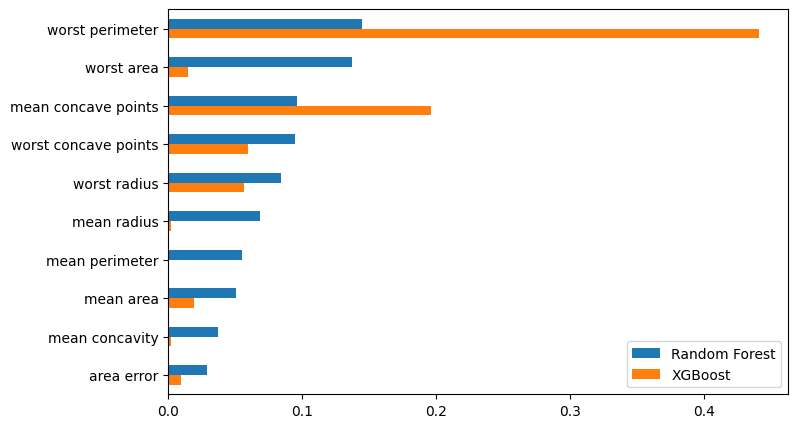

In [ ]:
rf = modelos["Random Forest"].fit(X_train, y_train)
xgb = modelos["XGBoost"].fit(X_train, y_train)
imp = pd.DataFrame({"Random Forest": rf.feature_importances_,
                    "XGBoost": xgb.feature_importances_},
                   index=X.columns)       # importancia por variable
top = imp.sort_values("Random Forest", ascending=False).head(10)
top.plot.barh(figsize=(8, 5)).invert_yaxis()   # las 10 primeras
top.round(3)

**Qué deberías ver:** Arriba, puntos cóncavos y radio del peor núcleo; XGBoost concentra cerca del 36 % en el radio.

✍️ **Interpreta:** ¿Coinciden estas variables con las de Boruta y la d de Cohen de la parte 1?

*Escribe aquí...*

#### Prompts listos para copiar · B1.4

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Importancia de variables: ¿qué usa
cada modelo?».

rf = modelos["Random Forest"].fit(X_train, y_train)
xgb = modelos["XGBoost"].fit(X_train, y_train)
imp = pd.DataFrame({"Random Forest": rf.feature_importances_,
                    "XGBoost": xgb.feature_importances_},
                   index=X.columns)       # importancia por variable
top = imp.sort_values("Random Forest", ascending=False).head(10)
top.plot.barh(figsize=(8, 5)).invert_yaxis()   # las 10 primeras
top.round(3)
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

rf = modelos["Random Forest"].fit(X_train, y_train)
xgb = modelos["XGBoost"].fit(X_train, y_train)
imp = pd.DataFrame({"Random Forest": rf.feature_importances_,
                    "XGBoost": xgb.feature_importances_},
                   index=X.columns)       # importancia por variable
top = imp.sort_values("Random Forest", ascending=False).head(10)
top.plot.barh(figsize=(8, 5)).invert_yaxis()   # las 10 primeras
top.round(3)

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «Importancia de variables: ¿qué usa cada modelo?»
de un laboratorio de ciencia de datos en Python. Mi pregunta es:
¿Coinciden estas variables con las de Boruta y la d de Cohen de la
parte 1? Ayúdame a interpretar la salida que pego al final. No uses
datos que no estén en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## Verificación del paso B1

Ejecuta esta celda antes de avanzar. Cada línea comprueba un resultado clave del paso.

In [ ]:
medias = {k: v.mean() for k, v in resultados.items()}
verificar(min(medias.values()) > auc_arbol.mean(),
          "todos los ensambles superan a un solo árbol")
verificar((en[-1].coef_ == 0).sum() > 0,
          "Elastic Net descartó variables (coeficiente 0)")

✅ CORRECTO: todos los ensambles superan a un solo árbol
✅ CORRECTO: Elastic Net descartó variables (coeficiente 0)


**Si todas las líneas muestran ✓**, continúa con el paso siguiente. **Si alguna muestra ✗**, vuelve a ejecutar los bloques del paso en orden, desde el primero; si persiste, usa el prompt «Si aparece un error» del bloque correspondiente o avisa en el chat indicando qué línea falló.

# Paso B2 · Ajuste bayesiano con Optuna

| | |
|---|---|
| **Para qué** | Encontrar buenos hiperparámetros de XGBoost con pocas pruebas. |
| **Prompt sugerido para la IA** | «¿Por qué la búsqueda bayesiana de Optuna necesita menos pruebas que una búsqueda en rejilla?» |
| **Tiempo sugerido** | 8 min |

In [ ]:

# Instalar Optuna si todavía no está disponible
%pip install -q optuna

# Importar Optuna
import optuna

print("Optuna instalado correctamente")
print("Versión:", optuna.__version__)


Optuna instalado correctamente
Versión: 5.0.0


## B2.1 · Optimizar XGBoost con Optuna

**Para qué:** Probar 30 combinaciones de hiperparámetros, guiadas por los resultados anteriores.

**Por qué así:** El muestreador TPE aprende qué zonas prometen y prueba más ahí; cada prueba se evalúa con los 5 pliegues de B0.3.

**Qué haces, paso a paso:**

1. Ubica la celda B2.1 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Espera alrededor de un minuto: Optuna prueba 30 combinaciones.
4. Compara con «Deberías ver».

In [ ]:
def objetivo(trial):                 # qué combinación probar
    params = {
      "n_estimators": trial.suggest_int("n_estimators", 100, 600),
      "max_depth": trial.suggest_int("max_depth", 2, 6),
      "learning_rate": trial.suggest_float("learning_rate",
                                           0.01, 0.3, log=True),
      "subsample": trial.suggest_float("subsample", 0.6, 1.0),
      "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10,
                                        log=True)}
    modelo = XGBClassifier(**params, random_state=SEMILLA)
    return cross_val_score(modelo, X_train, y_train, cv=cv,
                           scoring="roc_auc").mean()

estudio = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=30)    # 30 pruebas
print(round(estudio.best_value, 4), estudio.best_params)

[I 2026-11-15 18:19:06,939] A new study created in memory with name: no-name-282dbefc-4acc-4251-99df-13fac4333f13
[I 2026-11-15 18:19:09,733] Trial 0 finished with value: 0.9925413088072856 and parameters: {'n_estimators': 287, 'max_depth': 6, 'learning_rate': 0.1205712628744377, 'subsample': 0.8394633936788146, 'reg_lambda': 0.004207988669606638}. Best is trial 0 with value: 0.9925413088072856.
[I 2026-11-15 18:19:11,562] Trial 1 finished with value: 0.9920665111246365 and parameters: {'n_estimators': 178, 'max_depth': 2, 'learning_rate': 0.19030368381735815, 'subsample': 0.8404460046972835, 'reg_lambda': 0.679657809075816}. Best is trial 0 with value: 0.9925413088072856.
[I 2026-11-15 18:19:14,465] Trial 2 finished with value: 0.9921844356529383 and parameters: {'n_estimators': 110, 'max_depth': 6, 'learning_rate': 0.16967533607196555, 'subsample': 0.6849356442713105, 'reg_lambda': 0.005337032762603957}. Best is trial 0 with value: 0.9925413088072856.
[I 2026-11-15 18:19:19,671] Tria

0.9933 {'n_estimators': 506, 'max_depth': 2, 'learning_rate': 0.15509190199245168, 'subsample': 0.9408693336969087, 'reg_lambda': 2.5184188397181213}


**Qué deberías ver:** Mejor AUC cercano a 0,996 y los hiperparámetros elegidos. Tarda alrededor de un minuto.

#### Prompts listos para copiar · B2.1

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Optimizar XGBoost con Optuna».

def objetivo(trial):                 # qué combinación probar
    params = {
      "n_estimators": trial.suggest_int("n_estimators", 100, 600),
      "max_depth": trial.suggest_int("max_depth", 2, 6),
      "learning_rate": trial.suggest_float("learning_rate",
                                           0.01, 0.3, log=True),
      "subsample": trial.suggest_float("subsample", 0.6, 1.0),
      "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10,
                                        log=True)}
    modelo = XGBClassifier(**params, random_state=SEMILLA)
    return cross_val_score(modelo, X_train, y_train, cv=cv,
                           scoring="roc_auc").mean()

estudio = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=30)    # 30 pruebas
print(round(estudio.best_value, 4), estudio.best_params)
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

def objetivo(trial):                 # qué combinación probar
    params = {
      "n_estimators": trial.suggest_int("n_estimators", 100, 600),
      "max_depth": trial.suggest_int("max_depth", 2, 6),
      "learning_rate": trial.suggest_float("learning_rate",
                                           0.01, 0.3, log=True),
      "subsample": trial.suggest_float("subsample", 0.6, 1.0),
      "reg_lambda": trial.suggest_float("reg_lambda", 1e-3, 10,
                                        log=True)}
    modelo = XGBClassifier(**params, random_state=SEMILLA)
    return cross_val_score(modelo, X_train, y_train, cv=cv,
                           scoring="roc_auc").mean()

estudio = optuna.create_study(direction="maximize",
    sampler=optuna.samplers.TPESampler(seed=SEMILLA))
estudio.optimize(objetivo, n_trials=30)    # 30 pruebas
print(round(estudio.best_value, 4), estudio.best_params)

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## B2.2 · ¿Qué aprendió Optuna?

**Para qué:** Ver cómo mejoró la búsqueda prueba a prueba y qué hiperparámetro influyó más.

**Por qué así:** El historial muestra si la búsqueda se estabilizó: si las últimas pruebas ya no mejoran, más pruebas no ayudarían. La importancia de hiperparámetros indica cuáles conviene ajustar con cuidado.

**Qué haces, paso a paso:**

1. Ubica la celda B2.2 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.
5. Ejecuta la verificación del paso B2.

/tmp/ipykernel_1428/1609583577.py:5: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(estudio)   # cómo mejoró en las 30 pruebas


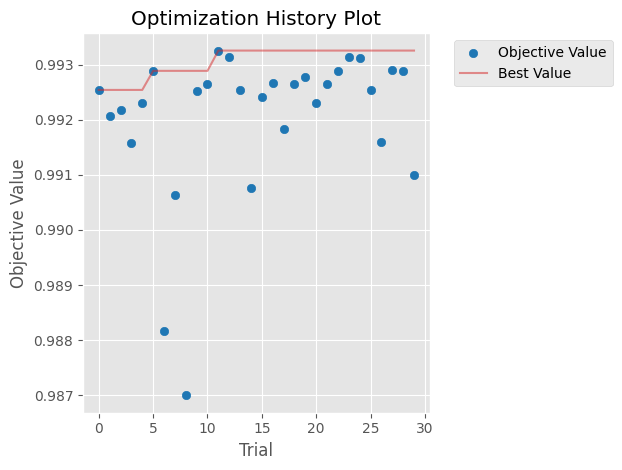

/tmp/ipykernel_1428/1609583577.py:7: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(estudio)      # qué hiperparámetro pesó más


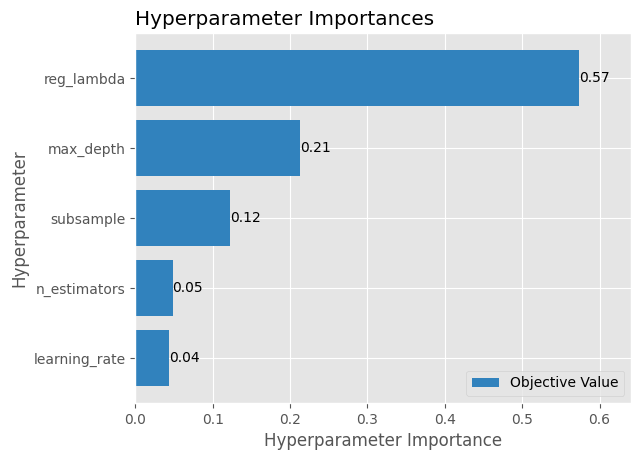

In [ ]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import (
    plot_optimization_history, plot_param_importances)

plot_optimization_history(estudio)   # cómo mejoró en las 30 pruebas
plt.show()
plot_param_importances(estudio)      # qué hiperparámetro pesó más
plt.show()

**Qué deberías ver:** Una curva que sube rápido y se aplana cerca de 0,996, y un gráfico de barras con la importancia de cada hiperparámetro.

✍️ **Interpreta:** ¿Valdría la pena hacer más de 30 pruebas? ¿Por qué?

*Escribe aquí...*

#### Prompts listos para copiar · B2.2

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «¿Qué aprendió Optuna?».

import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import (
    plot_optimization_history, plot_param_importances)

plot_optimization_history(estudio)   # cómo mejoró en las 30 pruebas
plt.show()
plot_param_importances(estudio)      # qué hiperparámetro pesó más
plt.show()
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import (
    plot_optimization_history, plot_param_importances)

plot_optimization_history(estudio)   # cómo mejoró en las 30 pruebas
plt.show()
plot_param_importances(estudio)      # qué hiperparámetro pesó más
plt.show()

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «¿Qué aprendió Optuna?» de un laboratorio de
ciencia de datos en Python. Mi pregunta es: ¿Valdría la pena hacer
más de 30 pruebas? ¿Por qué? Ayúdame a interpretar la salida que
pego al final. No uses datos que no estén en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## Verificación del paso B2

Ejecuta esta celda antes de avanzar. Cada línea comprueba un resultado clave del paso.

In [ ]:
verificar(len(estudio.trials) >= 15, "Optuna completó sus pruebas")
verificar(estudio.best_value > 0.98,
          "mejor AUC de Optuna mayor que 0,98")

✅ CORRECTO: Optuna completó sus pruebas
✅ CORRECTO: mejor AUC de Optuna mayor que 0,98


**Si todas las líneas muestran ✓**, continúa con el paso siguiente. **Si alguna muestra ✗**, vuelve a ejecutar los bloques del paso en orden, desde el primero; si persiste, usa el prompt «Si aparece un error» del bloque correspondiente o avisa en el chat indicando qué línea falló.

# Paso B3 · Stacking y blending

| | |
|---|---|
| **Para qué** | Combinar modelos heterogéneos con un meta-modelo, de dos maneras. |
| **Prompt sugerido para la IA** | «¿Qué son las predicciones fuera de pliegue en stacking y por qué evitan el sobreajuste del meta-modelo?» |
| **Tiempo sugerido** | 7 min |

In [ ]:

from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

print("Bibliotecas para stacking cargadas correctamente")


Bibliotecas para stacking cargadas correctamente


## B3.1 · Construir y evaluar un stacking

**Para qué:** Unir Random Forest, XGBoost optimizado y LightGBM con una regresión logística como meta-modelo.

**Por qué así:** El meta-modelo aprende con predicciones fuera de pliegue (cv=5), nunca con las que los modelos hicieron sobre sus propios datos.

**Qué haces, paso a paso:**

1. Ubica la celda B3.1 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».

In [ ]:
xgb_opt = XGBClassifier(**estudio.best_params,
                        random_state=SEMILLA)
stack = StackingClassifier(
    estimators=[("rf", modelos["Random Forest"]),
                ("xgb", xgb_opt),
                ("lgbm", modelos["LightGBM"])],
    final_estimator=LogisticRegression(max_iter=1000),  # meta
    cv=5)                         # predicciones fuera de pliegue

auc_stack = cross_val_score(stack, X_train, y_train, cv=cv,
                            scoring="roc_auc")
print("Stacking:", round(auc_stack.mean(), 4),
      "±", round(auc_stack.std(), 4))

Stacking: 0.9909 ± 0.005


**Qué deberías ver:** AUC cercano a 0,99 ± 0,01.

#### Prompts listos para copiar · B3.1

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Construir y evaluar un stacking».

xgb_opt = XGBClassifier(**estudio.best_params,
                        random_state=SEMILLA)
stack = StackingClassifier(
    estimators=[("rf", modelos["Random Forest"]),
                ("xgb", xgb_opt),
                ("lgbm", modelos["LightGBM"])],
    final_estimator=LogisticRegression(max_iter=1000),  # meta
    cv=5)                         # predicciones fuera de pliegue

auc_stack = cross_val_score(stack, X_train, y_train, cv=cv,
                            scoring="roc_auc")
print("Stacking:", round(auc_stack.mean(), 4),
      "±", round(auc_stack.std(), 4))
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

xgb_opt = XGBClassifier(**estudio.best_params,
                        random_state=SEMILLA)
stack = StackingClassifier(
    estimators=[("rf", modelos["Random Forest"]),
                ("xgb", xgb_opt),
                ("lgbm", modelos["LightGBM"])],
    final_estimator=LogisticRegression(max_iter=1000),  # meta
    cv=5)                         # predicciones fuera de pliegue

auc_stack = cross_val_score(stack, X_train, y_train, cv=cv,
                            scoring="roc_auc")
print("Stacking:", round(auc_stack.mean(), 4),
      "±", round(auc_stack.std(), 4))

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## B3.2 · Blending: combinar con un conjunto reservado

**Para qué:** Combinar los mismos modelos, pero entrenando el meta-modelo con un 25 % del entrenamiento reservado para ello.

**Por qué así:** Blending es más simple que stacking: en lugar de validación cruzada usa un conjunto aparte. A cambio, el meta-modelo aprende con menos casos (107 en lugar de 426).

**Qué haces, paso a paso:**

1. Ubica la celda B3.2 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.
5. Ejecuta la verificación del paso B3.

In [ ]:
X_ent, X_val, y_ent, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train,
    random_state=SEMILLA)          # 25 % para el meta-modelo
base = [modelos["Random Forest"], xgb_opt, modelos["LightGBM"]]
P_val = np.column_stack(
    [m.fit(X_ent, y_ent).predict_proba(X_val)[:, 1] for m in base])

auc_blend = cross_val_score(LogisticRegression(max_iter=1000),
                            P_val, y_val, cv=5, scoring="roc_auc")
print("Blending:", round(auc_blend.mean(), 4), "±",
      round(auc_blend.std(), 4))
print("Casos que usa el meta-modelo:", len(y_val))

Blending: 0.9945 ± 0.0072
Casos que usa el meta-modelo: 107


**Qué deberías ver:** AUC cercano a 0,996 ± 0,008 y 107 casos usados por el meta-modelo.

✍️ **Interpreta:** ¿Qué ventaja y qué desventaja tiene el blending frente al stacking de B3.1?

*Escribe aquí...*

#### Prompts listos para copiar · B3.2

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Blending: combinar con un conjunto
reservado».

X_ent, X_val, y_ent, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train,
    random_state=SEMILLA)          # 25 % para el meta-modelo
base = [modelos["Random Forest"], xgb_opt, modelos["LightGBM"]]
P_val = np.column_stack(
    [m.fit(X_ent, y_ent).predict_proba(X_val)[:, 1] for m in base])

auc_blend = cross_val_score(LogisticRegression(max_iter=1000),
                            P_val, y_val, cv=5, scoring="roc_auc")
print("Blending:", round(auc_blend.mean(), 4), "±",
      round(auc_blend.std(), 4))
print("Casos que usa el meta-modelo:", len(y_val))
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

X_ent, X_val, y_ent, y_val = train_test_split(
    X_train, y_train, test_size=0.25, stratify=y_train,
    random_state=SEMILLA)          # 25 % para el meta-modelo
base = [modelos["Random Forest"], xgb_opt, modelos["LightGBM"]]
P_val = np.column_stack(
    [m.fit(X_ent, y_ent).predict_proba(X_val)[:, 1] for m in base])

auc_blend = cross_val_score(LogisticRegression(max_iter=1000),
                            P_val, y_val, cv=5, scoring="roc_auc")
print("Blending:", round(auc_blend.mean(), 4), "±",
      round(auc_blend.std(), 4))
print("Casos que usa el meta-modelo:", len(y_val))

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «Blending: combinar con un conjunto reservado» de
un laboratorio de ciencia de datos en Python. Mi pregunta es: ¿Qué
ventaja y qué desventaja tiene el blending frente al stacking de
B3.1? Ayúdame a interpretar la salida que pego al final. No uses
datos que no estén en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## Verificación del paso B3

Ejecuta esta celda antes de avanzar. Cada línea comprueba un resultado clave del paso.

In [ ]:
verificar(auc_stack.mean() > 0.97, "stacking con AUC mayor que 0,97")
verificar(len(y_val) == 107, "blending con 107 casos de validación")

✅ CORRECTO: stacking con AUC mayor que 0,97
✅ CORRECTO: blending con 107 casos de validación


**Si todas las líneas muestran ✓**, continúa con el paso siguiente. **Si alguna muestra ✗**, vuelve a ejecutar los bloques del paso en orden, desde el primero; si persiste, usa el prompt «Si aparece un error» del bloque correspondiente o avisa en el chat indicando qué línea falló.

# Paso B4 · Evaluación honesta e IA responsable

| | |
|---|---|
| **Para qué** | Estimar sin optimismo, evaluar una sola vez y revisar el costo de los errores. |
| **Prompt sugerido para la IA** | «En un modelo de apoyo al diagnóstico de cáncer, ¿qué error es más grave: un falso negativo o un falso positivo? ¿Cómo afecta eso al umbral?» |
| **Tiempo sugerido** | 11 min |

In [ ]:

from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score
)

from xgboost import XGBClassifier

print("Bibliotecas para validación anidada cargadas correctamente")


Bibliotecas para validación anidada cargadas correctamente


## B4.1 · Validación cruzada anidada

**Para qué:** Evaluar el procedimiento completo, búsqueda de hiperparámetros incluida.

**Por qué así:** La búsqueda ocurre en la validación interna; la externa evalúa con datos que la búsqueda no vio.

**Qué haces, paso a paso:**

1. Ubica la celda B4.1 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».

In [ ]:
busqueda = RandomizedSearchCV(              # validación interna
    XGBClassifier(random_state=SEMILLA),
    {"max_depth": [2, 3, 4, 5], "learning_rate": [0.03, 0.1, 0.3],
     "n_estimators": [200, 400]},
    n_iter=8, cv=3, scoring="roc_auc", random_state=SEMILLA)
externa = StratifiedKFold(n_splits=5, shuffle=True,
                          random_state=SEMILLA + 1)

auc_anidada = cross_val_score(busqueda, X_train, y_train,
                              cv=externa, scoring="roc_auc")
print("AUC con CV anidada:", round(auc_anidada.mean(), 4))
print("Mejor AUC de Optuna:", round(estudio.best_value, 4))

AUC con CV anidada: 0.9915
Mejor AUC de Optuna: 0.9933


**Qué deberías ver:** Valores cercanos a 0,996 en ambos: aquí el ajuste casi no cambia el desempeño.

#### Prompts listos para copiar · B4.1

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Validación cruzada anidada».

busqueda = RandomizedSearchCV(              # validación interna
    XGBClassifier(random_state=SEMILLA),
    {"max_depth": [2, 3, 4, 5], "learning_rate": [0.03, 0.1, 0.3],
     "n_estimators": [200, 400]},
    n_iter=8, cv=3, scoring="roc_auc", random_state=SEMILLA)
externa = StratifiedKFold(n_splits=5, shuffle=True,
                          random_state=SEMILLA + 1)

auc_anidada = cross_val_score(busqueda, X_train, y_train,
                              cv=externa, scoring="roc_auc")
print("AUC con CV anidada:", round(auc_anidada.mean(), 4))
print("Mejor AUC de Optuna:", round(estudio.best_value, 4))
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

busqueda = RandomizedSearchCV(              # validación interna
    XGBClassifier(random_state=SEMILLA),
    {"max_depth": [2, 3, 4, 5], "learning_rate": [0.03, 0.1, 0.3],
     "n_estimators": [200, 400]},
    n_iter=8, cv=3, scoring="roc_auc", random_state=SEMILLA)
externa = StratifiedKFold(n_splits=5, shuffle=True,
                          random_state=SEMILLA + 1)

auc_anidada = cross_val_score(busqueda, X_train, y_train,
                              cv=externa, scoring="roc_auc")
print("AUC con CV anidada:", round(auc_anidada.mean(), 4))
print("Mejor AUC de Optuna:", round(estudio.best_value, 4))

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

In [ ]:

from sklearn.metrics import roc_auc_score

print("Función ROC-AUC importada correctamente")


Función ROC-AUC importada correctamente


## B4.2 · Evaluación final en la prueba

**Para qué:** Medir una sola vez, al final, con los 143 casos que nada vio.

**Por qué así:** Si la prueba se usa para elegir, se convierte en entrenamiento y la estimación deja de ser honesta.

**Qué haces, paso a paso:**

1. Ubica la celda B4.2 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».

In [ ]:
finales = {"Elastic Net": modelos["Elastic Net"],
           "XGBoost optimizado": xgb_opt,
           "Stacking": stack}

for nombre, m in finales.items():
    m.fit(X_train, y_train)                  # entrena con train
    p = m.predict_proba(X_test)[:, 1]        # evalúa en prueba
    auc = roc_auc_score(y_test, p)
    print(f"{nombre:20s} AUC en prueba = {auc:.4f}")

Elastic Net          AUC en prueba = 0.9979
XGBoost optimizado   AUC en prueba = 0.9927
Stacking             AUC en prueba = 0.9983


**Qué deberías ver:** AUC en prueba entre 0,98 y 0,99 en los tres modelos.

#### Prompts listos para copiar · B4.2

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Evaluación final en la prueba».

finales = {"Elastic Net": modelos["Elastic Net"],
           "XGBoost optimizado": xgb_opt,
           "Stacking": stack}

for nombre, m in finales.items():
    m.fit(X_train, y_train)                  # entrena con train
    p = m.predict_proba(X_test)[:, 1]        # evalúa en prueba
    auc = roc_auc_score(y_test, p)
    print(f"{nombre:20s} AUC en prueba = {auc:.4f}")
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

finales = {"Elastic Net": modelos["Elastic Net"],
           "XGBoost optimizado": xgb_opt,
           "Stacking": stack}

for nombre, m in finales.items():
    m.fit(X_train, y_train)                  # entrena con train
    p = m.predict_proba(X_test)[:, 1]        # evalúa en prueba
    auc = roc_auc_score(y_test, p)
    print(f"{nombre:20s} AUC en prueba = {auc:.4f}")

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

In [ ]:

from sklearn.metrics import confusion_matrix

print("Matriz de confusión importada correctamente")


Matriz de confusión importada correctamente


## B4.3 · IA responsable: ¿cuántos malignos no detecta?

**Para qué:** Contar los errores que importan: tumores malignos clasificados como benignos.

**Por qué así:** Un AUC alto no dice cuántos malignos se escapan. Bajar el umbral detecta más, pero aumenta las falsas alarmas: es una decisión clínica, no solo estadística.

**Qué haces, paso a paso:**

1. Ubica la celda B4.3 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Escribe tu interpretación en ✍️.
5. Ejecuta la verificación del paso B4.

In [ ]:
en = modelos["Elastic Net"]           # ya entrenado en B4.2
p = en.predict_proba(X_test)[:, 1]    # probabilidad de maligno
for umbral in [0.5, 0.3, 0.1]:
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Umbral {umbral}: malignos no detectados = {fn}, "
          f"falsas alarmas = {fp}, sensibilidad = {tp/(tp+fn):.3f}")

Umbral 0.5: malignos no detectados = 3, falsas alarmas = 0, sensibilidad = 0.943
Umbral 0.3: malignos no detectados = 1, falsas alarmas = 1, sensibilidad = 0.981
Umbral 0.1: malignos no detectados = 1, falsas alarmas = 8, sensibilidad = 0.981


**Qué deberías ver:** Con 0,5: 3 malignos no detectados y 1 falsa alarma; con 0,1: 2 y 12.

✍️ **Interpreta:** ¿Qué umbral elegirías y quién debería decidirlo? ¿Por qué este modelo no es una herramienta diagnóstica?

*Escribe aquí...*

#### Prompts listos para copiar · B4.3

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «IA responsable: ¿cuántos malignos no
detecta?».

en = modelos["Elastic Net"]           # ya entrenado en B4.2
p = en.predict_proba(X_test)[:, 1]    # probabilidad de maligno
for umbral in [0.5, 0.3, 0.1]:
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Umbral {umbral}: malignos no detectados = {fn}, "
          f"falsas alarmas = {fp}, sensibilidad = {tp/(tp+fn):.3f}")
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

en = modelos["Elastic Net"]           # ya entrenado en B4.2
p = en.predict_proba(X_test)[:, 1]    # probabilidad de maligno
for umbral in [0.5, 0.3, 0.1]:
    pred = (p >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"Umbral {umbral}: malignos no detectados = {fn}, "
          f"falsas alarmas = {fp}, sensibilidad = {tp/(tp+fn):.3f}")

Error:
[pega aquí el mensaje de error completo]
```

**3. Para interpretar el resultado** (copia el recuadro y reemplaza la última línea por la salida que obtuviste):

```text
Ejecuté el bloque «IA responsable: ¿cuántos malignos no detecta?» de
un laboratorio de ciencia de datos en Python. Mi pregunta es: ¿Qué
umbral elegirías y quién debería decidirlo? ¿Por qué este modelo no
es una herramienta diagnóstica? Ayúdame a interpretar la salida que
pego al final. No uses datos que no estén en la salida.

Salida:
[pega aquí la salida del bloque]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## Verificación del paso B4

Ejecuta esta celda antes de avanzar. Cada línea comprueba un resultado clave del paso.

In [ ]:
verificar(auc_anidada.mean() > 0.97,
          "validación anidada mayor que 0,97")
verificar(fn >= 1,
          "hay malignos no detectados: revisa el umbral")

✅ CORRECTO: validación anidada mayor que 0,97
✅ CORRECTO: hay malignos no detectados: revisa el umbral


**Si todas las líneas muestran ✓**, continúa con el paso siguiente. **Si alguna muestra ✗**, vuelve a ejecutar los bloques del paso en orden, desde el primero; si persiste, usa el prompt «Si aparece un error» del bloque correspondiente o avisa en el chat indicando qué línea falló.

# Paso B5 · Automatizar la comparación

| | |
|---|---|
| **Para qué** | Repetir todo el proceso con una sola línea, para aplicarlo a tu dataset. |
| **Prompt sugerido para la IA** | «Adapta esta función para que también calcule la sensibilidad de cada modelo: [pega la función]» |
| **Tiempo sugerido** | 3 min |

## B5.1 · Una función reutilizable

**Para qué:** Convertir los pasos B0 a B4 en una función que divide, valida, evalúa y guarda la tabla.

**Por qué así:** Automatizar evita errores al repetir y garantiza que todos los modelos se evalúen igual. Con tu dataset, solo cambias X e y.

**Qué haces, paso a paso:**

1. Ubica la celda B5.1 (panel Índice).
2. Ejecútala con Ctrl + Enter.
3. Compara con «Deberías ver».
4. Ejecuta la verificación del paso B5.

In [ ]:
def comparar_modelos(X, y, modelos, semilla=SEMILLA):
    """Divide, valida y devuelve una tabla comparativa."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=semilla)
    cv = StratifiedKFold(5, shuffle=True, random_state=semilla)
    filas = []
    for nombre, m in modelos.items():
        auc = cross_val_score(m, X_tr, y_tr, cv=cv,
                              scoring="roc_auc")
        m.fit(X_tr, y_tr)
        prueba = roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])
        filas.append({"modelo": nombre, "AUC_cv": auc.mean(),
                      "desv_cv": auc.std(), "AUC_prueba": prueba})
    return pd.DataFrame(filas).round(4)

tabla = comparar_modelos(X, y, modelos)        # una sola línea
tabla.to_csv("comparacion_modelos.csv", index=False)
tabla

,modelo,AUC_cv,desv_cv,AUC_prueba
0,Elastic Net,0.9922,0.0070,0.9979
1,Random Forest,0.9879,0.0095,0.9957
2,XGBoost,0.9910,0.0055,0.9960
3,LightGBM,0.9919,0.0045,0.9969


**Qué deberías ver:** Una tabla con AUC de validación, desviación y AUC de prueba por modelo, y el archivo comparacion_modelos.csv.

#### Prompts listos para copiar · B5.1

**1. Para entender el código** (copia todo el recuadro y pégalo en el chat de IA):

```text
Estoy en un laboratorio de ciencia de datos en Python (Google
Colab). Explícame línea por línea qué hace este código y por qué se
usa en este paso del análisis: «Una función reutilizable».

def comparar_modelos(X, y, modelos, semilla=SEMILLA):
    """Divide, valida y devuelve una tabla comparativa."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=semilla)
    cv = StratifiedKFold(5, shuffle=True, random_state=semilla)
    filas = []
    for nombre, m in modelos.items():
        auc = cross_val_score(m, X_tr, y_tr, cv=cv,
                              scoring="roc_auc")
        m.fit(X_tr, y_tr)
        prueba = roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])
        filas.append({"modelo": nombre, "AUC_cv": auc.mean(),
                      "desv_cv": auc.std(), "AUC_prueba": prueba})
    return pd.DataFrame(filas).round(4)

tabla = comparar_modelos(X, y, modelos)        # una sola línea
tabla.to_csv("comparacion_modelos.csv", index=False)
tabla
```

**2. Si aparece un error** (copia el recuadro y reemplaza la última línea por el mensaje de error):

```text
Al ejecutar este código en Python (Google Colab) obtengo el error
que pego al final. Explícame la causa y cómo corregirlo sin cambiar
el propósito del análisis.

def comparar_modelos(X, y, modelos, semilla=SEMILLA):
    """Divide, valida y devuelve una tabla comparativa."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=0.25, stratify=y, random_state=semilla)
    cv = StratifiedKFold(5, shuffle=True, random_state=semilla)
    filas = []
    for nombre, m in modelos.items():
        auc = cross_val_score(m, X_tr, y_tr, cv=cv,
                              scoring="roc_auc")
        m.fit(X_tr, y_tr)
        prueba = roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])
        filas.append({"modelo": nombre, "AUC_cv": auc.mean(),
                      "desv_cv": auc.std(), "AUC_prueba": prueba})
    return pd.DataFrame(filas).round(4)

tabla = comparar_modelos(X, y, modelos)        # una sola línea
tabla.to_csv("comparacion_modelos.csv", index=False)
tabla

Error:
[pega aquí el mensaje de error completo]
```

Recuerda: ejecuta, verifica contra la salida real y anota en la declaración de uso de IA lo que usaste.

## Verificación del paso B5

Ejecuta esta celda antes de avanzar. Cada línea comprueba un resultado clave del paso.

In [ ]:
import os
verificar(os.path.exists("comparacion_modelos.csv")
          and len(tabla) == 4,
          "tabla comparativa de 4 modelos guardada")

✅ CORRECTO: tabla comparativa de 4 modelos guardada


**Si todas las líneas muestran ✓**, continúa con el paso siguiente. **Si alguna muestra ✗**, vuelve a ejecutar los bloques del paso en orden, desde el primero; si persiste, usa el prompt «Si aparece un error» del bloque correspondiente o avisa en el chat indicando qué línea falló.

In [ ]:



import pandas as pd

# Pegar la dirección exacta copiada desde "Crudo" en GitHub
ARCHIVO = "https://raw.githubusercontent.com/edgmattounhv-boop/segunda-especilizaci-n/refs/heads/main/s3s4-laboratorio/s3s4-laboratorio/data/processed/wdbc_limpio.csv"

print("Dirección utilizada:", ARCHIVO)

try:
    df = pd.read_csv(ARCHIVO)

    print("BASE DE DATOS CARGADA CORRECTAMENTE")
    print("Dimensiones:", df.shape)
    print("Columnas:", df.columns.tolist())
    print("Diagnósticos:")
    print(df["diagnosis"].value_counts())

    display(df.head())

except Exception as e:
    print("ERROR AL CARGAR EL ARCHIVO:")
    print(type(e).__name__, str(e))


Dirección utilizada: https://raw.githubusercontent.com/edgmattounhv-boop/segunda-especilizaci-n/refs/heads/main/s3s4-laboratorio/s3s4-laboratorio/data/processed/wdbc_limpio.csv
BASE DE DATOS CARGADA CORRECTAMENTE
Dimensiones: (569, 32)
Columnas: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']
Diagnósticos:
diagnosis
Benigno    357
Maligno    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,Maligno,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,Maligno,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,Maligno,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,Maligno,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,Maligno,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# Paso B6 · Automatización con tu dataset

| | |
|---|---|
| **Para qué** | Aplicar en una sola instrucción todo el procedimiento del laboratorio a tu propio dataset. |
| **Cuándo** | Después de la clase, como primer paso del reporte comparativo. |

La función `analisis_automatico()`:

1. Lee tu archivo y quita las columnas que indiques (por ejemplo, el identificador).
2. **Detecta el tipo de problema:** clasificación (respuesta categórica o con 10 valores distintos o menos) o regresión (respuesta numérica continua).
3. Codifica las variables categóricas, imputa los faltantes con la mediana dentro del pipeline (sin fuga) y elimina las variables constantes.
4. Divide 75/25 (estratificado en clasificación) y compara Elastic Net, Random Forest, XGBoost y LightGBM con validación cruzada de 5 pliegues: AUC en clasificación, RMSE en regresión.
5. **Aplica el criterio de parsimonia:** si la diferencia entre el mejor modelo y Elastic Net es menor que la variabilidad, lo indica.
6. Guarda la tabla en `comparacion_mi_dataset.csv`.

**IA responsable:** usa la versión anonimizada de tu dataset. Si lo lees desde GitHub, el repositorio debe ser público o debes subir el archivo al panel Archivos de Colab (se borra al cerrar la sesión).

**Prompt para adaptar la configuración a tu dataset** (copia el recuadro, ejecuta antes `pd.read_csv(ARCHIVO).dtypes` y pega su resultado al final):

```text
Estoy preparando un análisis predictivo con mi dataset. Estas son
sus columnas y tipos. Indícame qué columna conviene usar como
variable respuesta según mi pregunta de investigación, qué columnas
debería excluir (identificadores, fechas, variables que se conocen
después del resultado) y por qué. Mi pregunta de investigación es:
[escribe tu pregunta]

Columnas y tipos:
[pega aquí el resultado de pd.read_csv(ARCHIVO).dtypes]
```

In [ ]:



import pandas as pd

SEMILLA = 42

# Ruta correcta y verificada en GitHub
ARCHIVO = (
    "https://raw.githubusercontent.com/"
    "edgmattounhv-boop/"
    "segunda-especilizaci-n/"
    "refs/heads/main/"
    "s3s4-laboratorio/s3s4-laboratorio/"
    "data/processed/wdbc_limpio.csv"
)

RESPUESTA = "diagnosis"
EXCLUIR = ["id"]

# Comprobar conexión GitHub - Colab
df = pd.read_csv(ARCHIVO)

print("CONEXIÓN CON GITHUB CORRECTA")
print("Observaciones:", df.shape[0])
print("Variables:", df.shape[1])
print("Variable dependiente:", RESPUESTA)
print("Distribución del diagnóstico:")
print(df["diagnosis"].value_counts())

display(df.head())



CONEXIÓN CON GITHUB CORRECTA
Observaciones: 569
Variables: 32
Variable dependiente: diagnosis
Distribución del diagnóstico:
diagnosis
Benigno    357
Maligno    212
Name: count, dtype: int64


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,Maligno,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,Maligno,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,Maligno,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,Maligno,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,Maligno,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:


# ==================================================
# PASO B6 - CONFIGURACION E IMPORTACIONES COMPLETAS
# ==================================================

import numpy as np
import pandas as pd

# Semilla de reproducibilidad
SEMILLA = 42

# Preparacion de datos
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    LabelEncoder
)
from sklearn.pipeline import make_pipeline

# Particion y validacion cruzada
from sklearn.model_selection import (
    train_test_split,
    KFold,
    StratifiedKFold,
    cross_val_score
)

# Metricas
from sklearn.metrics import get_scorer

# Modelos lineales
from sklearn.linear_model import (
    ElasticNet,
    LogisticRegression
)

# Random Forest
from sklearn.ensemble import (
    RandomForestClassifier,
    RandomForestRegressor
)

# XGBoost
from xgboost import (
    XGBClassifier,
    XGBRegressor
)

# LightGBM
from lightgbm import (
    LGBMClassifier,
    LGBMRegressor
)

print("TODAS LAS BIBLIOTECAS DE B6 ESTAN CARGADAS")
print("Semilla:", SEMILLA)


TODAS LAS BIBLIOTECAS DE B6 ESTAN CARGADAS
Semilla: 42


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.metrics import get_scorer
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import ElasticNet
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

def analisis_automatico(archivo, respuesta, excluir=(),
                        semilla=SEMILLA):
    df = pd.read_csv(archivo)
    df = df.drop(columns=list(excluir), errors="ignore")
    df = df.dropna(subset=[respuesta])
    y = df.pop(respuesta)
    X = pd.get_dummies(df, drop_first=True).astype(float)  # codifica
    X = X.loc[:, X.std() > 0]                # quita las constantes
    clasif = ((not pd.api.types.is_numeric_dtype(y))
              or y.nunique() <= 10)
    imp = lambda m: make_pipeline(SimpleImputer(strategy="median"), m)
    if clasif:
        y = pd.Series(LabelEncoder().fit_transform(y), index=y.index)
        k = y.nunique()
        metrica = "roc_auc" if k == 2 else "roc_auc_ovr"
        cv = StratifiedKFold(5, shuffle=True, random_state=semilla)
        modelos = {
          "Elastic Net": imp(make_pipeline(StandardScaler(),
              LogisticRegression(penalty="elasticnet", solver="saga",
                                 l1_ratio=0.5, max_iter=5000))),
          "Random Forest": imp(RandomForestClassifier(300,
                                 random_state=semilla)),
          "XGBoost": XGBClassifier(n_estimators=300, max_depth=3,
              learning_rate=0.05, random_state=semilla),
          "LightGBM": LGBMClassifier(n_estimators=300, verbose=-1,
              learning_rate=0.05, random_state=semilla)}
        estrato = y
        print(f"Clasificación con {k} clases. Proporciones:",
              y.value_counts(normalize=True).round(3).to_dict())
    else:
        metrica = "neg_root_mean_squared_error"
        cv = KFold(5, shuffle=True, random_state=semilla)
        modelos = {
          "Elastic Net": imp(make_pipeline(StandardScaler(),
                                           ElasticNet(alpha=0.1))),
          "Random Forest": imp(RandomForestRegressor(300,
                                 random_state=semilla)),
          "XGBoost": XGBRegressor(n_estimators=300, max_depth=3,
              learning_rate=0.05, random_state=semilla),
          "LightGBM": LGBMRegressor(n_estimators=300, verbose=-1,
              learning_rate=0.05, random_state=semilla)}
        estrato = None
        print("Regresión: la métrica es el RMSE (menor es mejor)")
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25,
        stratify=estrato, random_state=semilla)
    print(f"Entrenamiento: {len(X_tr)} | Prueba: {len(X_te)}")
    filas = []
    for nombre, m in modelos.items():
        s = cross_val_score(m, X_tr, y_tr, cv=cv, scoring=metrica)
        m.fit(X_tr, y_tr)
        prueba = get_scorer(metrica)(m, X_te, y_te)
        signo = -1 if metrica.startswith("neg") else 1
        filas.append({"modelo": nombre, "cv_media": signo * s.mean(),
                      "cv_desv": s.std(), "prueba": signo * prueba})
    tabla = pd.DataFrame(filas).round(4)
    mejor = tabla.sort_values("cv_media",
        ascending=not clasif).iloc[0]
    base = tabla.set_index("modelo").loc["Elastic Net"]
    dif = abs(mejor["cv_media"] - base["cv_media"])
    if mejor["modelo"] == "Elastic Net":
        print("Criterio: Elastic Net es el mejor y el más simple")
    elif dif <= tabla["cv_desv"].max():
        print("Criterio: la diferencia con Elastic Net es menor que "
              "la variabilidad: por parsimonia, prefiere Elastic Net")
    else:
        print(f"Criterio: {mejor['modelo']} supera a Elastic Net por "
              "más que la variabilidad de la validación cruzada.")
    tabla.to_csv("comparacion_mi_dataset.csv", index=False)
    return tabla

analisis_automatico(ARCHIVO, RESPUESTA, EXCLUIR)

Clasificación con 2 clases. Proporciones: {0: 0.627, 1: 0.373}
Entrenamiento: 426 | Prueba: 143
Criterio: la diferencia con Elastic Net es menor que la variabilidad: por parsimonia, prefiere Elastic Net


,modelo,cv_media,cv_desv,prueba
0,Elastic Net,0.9910,0.0098,0.9975
1,Random Forest,0.9879,0.0095,0.9957
2,XGBoost,0.9910,0.0055,0.9960
3,LightGBM,0.9919,0.0045,0.9969


**Qué deberías ver:** el tipo de problema detectado, las proporciones de clases (o la indicación de regresión), el tamaño de entrenamiento y prueba, el criterio de elección y la tabla comparativa.

In [ ]:

# Recuperar los resultados de validación disponibles
import numpy as np

objetos = {
    "Un solo árbol": "auc_arbol",
    "Random Forest, Elastic Net, XGBoost y LightGBM": "resultados",
    "Stacking": "auc_stack",
    "XGBoost con Optuna": "estudio",
    "Validación anidada": "auc_anidada"
}

for nombre, variable in objetos.items():
    if variable in globals():
        valor = globals()[variable]
        print(f"\n{nombre}:")
        if variable == "resultados":
            for modelo, datos in valor.items():
                datos = np.asarray(datos)
                print(modelo, round(datos.mean(), 4),
                      "±", round(datos.std(), 4))
        elif variable == "estudio":
            print("Mejor AUC:", round(valor.best_value, 4))
        else:
            datos = np.asarray(valor)
            print("AUC:", round(datos.mean(), 4),
                  "±", round(datos.std(), 4))
    else:
        print(f"{nombre}: no disponible en esta sesión")


Un solo árbol: no disponible en esta sesión
Random Forest, Elastic Net, XGBoost y LightGBM: no disponible en esta sesión
Stacking: no disponible en esta sesión
XGBoost con Optuna: no disponible en esta sesión
Validación anidada: no disponible en esta sesión


# Cierre de la parte 2 · Elección del modelo con criterio

| Modelo | AUC en validación cruzada (media ± desviación) | AUC en prueba | Interpretabilidad | Comentario |
|---|---|---|---|---|
| Un solo árbol | | — | Muy alta | |
| Elastic Net | | | Alta: coeficientes por variable | |
| Random Forest | | | Media | |
| XGBoost optimizado | | | Media | |
| Stacking | | | Baja | |

✍️ **¿Qué modelo elegirías para tu investigación y por qué?** Considera si las diferencias superan la variabilidad, la parsimonia, la interpretabilidad, el costo de los errores (B4.3) y la coherencia con tus hipótesis.

*Para esta investigación consideraría seleccionar el modelo de regresión logística regularizada mediante Elastic Net, siempre que sus indicadores de validación cruzada y evaluación final sean comparables con los obtenidos por XGBoost optimizado y Stacking.

Esta elección se fundamenta en el principio de parsimonia, debido a que Elastic Net combina regularización L1 y L2, permite controlar el sobreajuste y facilita la interpretación de la contribución de las variables predictoras. Estas características son relevantes cuando se trabaja con información relacionada con el diagnóstico de tumores.

Sin embargo, la selección definitiva debe sustentarse en los valores de ROC-AUC, su variabilidad entre pliegues y los resultados de la evaluación independiente. Si un modelo más complejo presenta una mejora sustancial y estable, especialmente en la detección de casos malignos, deberá considerarse su elección.

Asimismo, los falsos negativos tienen especial importancia, porque representan casos malignos que el sistema no detecta. Por tanto, la decisión no debe sustentarse exclusivamente en el ROC-AUC, sino también en la sensibilidad, especificidad y consecuencias de los errores de clasificación.

En conclusión, priorizaría un modelo que ofrezca un equilibrio verificable entre capacidad predictiva, estabilidad, interpretabilidad y seguridad, reconociendo que su aplicación clínica requeriría validación externa y supervisión profesional.*

## Ficha del modelo (IA responsable)

| Campo | Tu respuesta |
|---|---|
| Uso previsto | *Investigación académica para comparar algoritmos de clasificación de tumores benignos y malignos. No constituye una herramienta diagnóstica clínica* |
| Datos de entrenamiento | *Wisconsin Diagnostic Breast Cancer (WDBC), disponible mediante el repositorio GitHub del laboratorio. Base de 569 registros: 357 benignos y 212 malignos* |
| Métricas y variabilidad |*ROC-AUC promedio, desviación estándar de cinco pliegues de validación cruzada y evaluación sobre el conjunto de prueba. Complementariamente, sensibilidad y matriz de confusión* |
| Errores que más importan | *Los falsos negativos: tumores malignos clasificados incorrectamente como benignos. También deben considerarse los falsos positivos y sus consecuencias.* |
| Limitaciones | *Base de datos histórica y específica; ausencia de validación clínica externa para este ejercicio; posibles diferencias entre poblaciones y centros médicos; dependencia de la calidad y representatividad de los datos* |

## Guardar en GitHub

1. **Archivo → Guardar una copia en GitHub.**
2. La primera vez, autoriza el acceso de Colab a tu cuenta de GitHub.
3. Elige tu repositorio (el mismo de la parte 1) y la rama `main`.
4. En la ruta escribe `notebooks/S3S4_parte2.ipynb`.
5. Escribe un mensaje de commit claro, marca **Incluir un vínculo a Colab** y confirma.

## Declaración de uso de IA

| Herramienta | Para qué la usé | Cómo verifiqué el resultado |
|---|---|---|
| ChatGPT | *Apoyo para identificar errores de programación, revisar importaciones de Python, configurar rutas GitHub–Colab y comprender los métodos de aprendizaje automático* | *Ejecuté los códigos en Google Colab y contrasté las salidas con los resultados del laboratorio* |
|Google Colab | *Ejecutar Python, entrenar y evaluar modelos, realizar validación cruzada y generar resultados* | *Revisé las salidas, mensajes de error, dimensiones de los datos y métricas obtenidas* |
|GitHub | *Almacenar los archivos del proyecto y permitir su lectura desde Colab* | *Comprobé la carga directa del CSV y sus 569 observaciones y 32 columnas* |